Question 1 – Manual Neural Network (CIFAR-10)

In [5]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
from pathlib import Path
import sys
torch.manual_seed(42)
device = torch.device(
"cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [2]:
# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat','deer', 'dog', 'frog', 'horse', 'ship', 'truck')


100%|██████████| 170M/170M [1:06:57<00:00, 42.4kB/s] 


In [6]:

from torch.utils.data import DataLoader, random_split

torch.manual_seed(42)

# Split existing training dataset into training and validation
full_trainset = trainset

trainset, valset = random_split(
    full_trainset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Create new DataLoaders
trainloader = DataLoader(
    trainset, batch_size=50, shuffle=True, num_workers=0
)

valloader = DataLoader(
    valset, batch_size=50, shuffle=False, num_workers=0
)

testloader = DataLoader(
    testset, batch_size=50, shuffle=False, num_workers=0
)

print("Training:", len(trainset))
print("Validation:", len(valset))
print("Testing:", len(testset))


Training: 45000
Validation: 5000
Testing: 10000


In [7]:

# Network parameters
Din = 3 * 32 * 32
H = 100
K = 10
std = 1e-2

w1 = torch.randn(Din, H, device=device) * std
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * std
b2 = torch.zeros(K, device=device)

iterations = 10
lr = 0.1
lr_decay = 0.9
reg = 0

loss_history = []
train_acc_history = []
val_acc_history = []
train_loss_history = []
val_loss_history = []


In [8]:

def forward(x):
    z1 = x.mm(w1) + b1
    a1 = torch.sigmoid(z1)
    z2 = a1.mm(w2) + b2
    return a1, z2


def evaluate(loader):
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            x = inputs.view(inputs.shape[0], -1)

            _, scores = forward(x)

            loss = nn.functional.cross_entropy(scores, labels)
            predicted = scores.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


In [9]:

for t in range(iterations):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    progress = tqdm(
        trainloader,
        desc=f"Epoch {t+1:2d}/{iterations}",
        ascii="─━",
        bar_format="{desc} {percentage:3.0f}% |{bar}| {n_fmt}/{total_fmt}",
        leave=True,
        file=sys.stdout
    )

    for inputs, labels in progress:
        inputs = inputs.to(device)
        labels = labels.to(device)

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        a1, z2 = forward(x_train)
        y_pred = torch.softmax(z2, dim=1)

        # Cross-entropy loss
        loss = nn.functional.cross_entropy(z2, labels)

        loss_history.append(loss.item())
        running_loss += loss.item() * Ntr

        # Manual backpropagation
        dz2 = y_pred.clone()
        dz2[torch.arange(Ntr, device=device), labels] -= 1
        dz2 /= Ntr

        dw2 = a1.t().mm(dz2)
        db2 = dz2.sum(dim=0)

        da1 = dz2.mm(w2.t())
        dz1 = da1 * a1 * (1 - a1)

        dw1 = x_train.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

        predicted = z2.argmax(dim=1)
        correct_train += (predicted == labels).sum().item()
        total_train += Ntr

    train_loss = running_loss / total_train
    train_acc = 100 * correct_train / total_train

    # Validation after the epoch
    val_loss, val_acc = evaluate(valloader)

    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    lr *= lr_decay


Epoch  1/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.9141 | Train Acc: 30.81% | Val Loss: 1.7751 | Val Acc: 38.18%
Epoch  2/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.7283 | Train Acc: 39.20% | Val Loss: 1.6939 | Val Acc: 42.14%
Epoch  3/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.6644 | Train Acc: 42.15% | Val Loss: 1.6690 | Val Acc: 41.54%
Epoch  4/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.6169 | Train Acc: 43.80% | Val Loss: 1.6251 | Val Acc: 43.88%
Epoch  5/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.5775 | Train Acc: 45.25% | Val Loss: 1.6083 | Val Acc: 43.98%
Epoch  6/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.5434 | Train Acc: 46.75% | Val Loss: 1.5893 | Val Acc: 45.18%
Epoch  7/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.5131 | Train Acc: 47.86% | Val Loss: 1.5742 | Val Acc: 45.32%
Epoch  8/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.4874 | Train Acc: 48.94% | Val Loss: 1.5672 | Val Acc: 46.44%
Epoch  9/10 100% |━━━━━━━━━━| 900/900
Train Loss: 1.4629 | Train Acc: 49.61% | Val Loss:

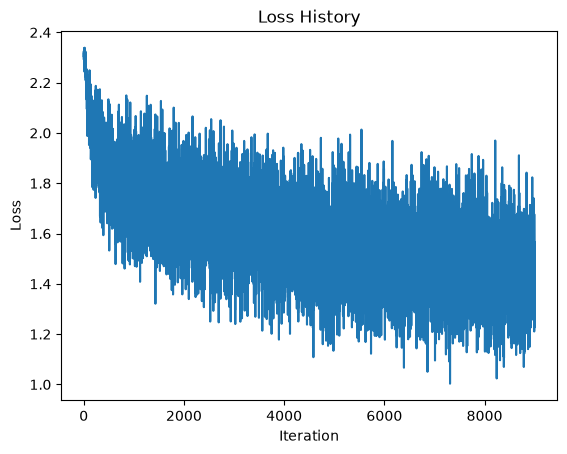

In [11]:

import matplotlib.pyplot as plt
from pathlib import Path

# Results folder at project root
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")

# Save to results folder
plt.savefig(results_dir / "Q1_loss_history.png", dpi=300)

plt.show()


In [12]:

# Final evaluation
train_loss, train_acc = evaluate(trainloader)
test_loss, test_acc = evaluate(testloader)

print("\nFINAL RESULTS AFTER 10 EPOCHS")
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")




FINAL RESULTS AFTER 10 EPOCHS
Training accuracy: 51.21%
Test accuracy: 46.64%
